
# 7.5 Test ENet zbig models on transformed validation datasets

This notebook evaluates only the saved ENet zbig `.h5` models, using the datasets prepared by `1.5.transform_enet_zbig.ipynb`.

It saves protein-level and tissue-level results in the same style as notebook 7, but in a separate output folder:

```text
../results_comparison_enet_zbig_transformed/
```

Main outputs:

```text
res_enet_zbig__eval_predictions_long.parquet
res_enet_zbig__eval_metrics_by_protein.csv
res_enet_zbig__feature_coverage.csv
res_enet_zbig__eval_metrics_by_tissue.csv
res_enet_zbig__eval_metrics_by_tissue_tableS6_format.csv
res_enet_zbig__eval_metrics_by_tissue_protein.csv

eval_metrics_by_protein.csv
eval_metrics_by_tissue.csv
eval_metrics_by_tissue_tableS6_format.csv
feature_coverage.csv
model_inventory.csv
```

Cosine similarity is computed at both protein and tissue levels and is exported as `test_cosine_similarity` plus the TableS6-format extra column `cosine`.


In [1]:

from pathlib import Path
import sys

CWD = Path.cwd().resolve()
_src_search_roots = []
for _base in [CWD, *CWD.parents]:
    for _candidate in [_base, _base / "notebooks", _base / "notebooks2"]:
        if _candidate not in _src_search_roots:
            _src_search_roots.append(_candidate)

for _candidate in _src_search_roots:
    if (_candidate / "src" / "utils_val.py").exists():
        if str(_candidate) not in sys.path:
            sys.path.insert(0, str(_candidate))
        print("Using validation utilities from:", _candidate / "src" / "utils_val.py")
        break

try:
    import src.utils_val as uv
    from src.utils_val import *
except Exception as exc:
    uv = None
    print("src.utils_val not imported; notebook will use local helpers only:", type(exc).__name__, exc)


def sync_utils_globals(namespace=None, **kwargs):
    if uv is None:
        return None
    ns = globals() if namespace is None else namespace
    clean = {}
    for _name, _value in dict(ns).items():
        if str(_name).startswith("__"):
            continue
        clean[_name] = _value
    clean.update(kwargs)
    if hasattr(uv, "configure_runtime_globals"):
        uv.configure_runtime_globals(**clean)
    elif hasattr(uv, "set_module_globals"):
        try:
            uv.set_module_globals(clean)
        except TypeError:
            uv.set_module_globals(**clean)
    else:
        for _name, _value in clean.items():
            setattr(uv, _name, _value)
    return None

sync_utils_globals()


Using validation utilities from: C:\Users\hp\Desktop\new_pRNA\notebooks2\src\utils_val.py


In [2]:

import os
import re
import json
import lzma
import gzip
import zlib
import pickle
import hashlib
import warnings
from pathlib import Path

import h5py
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")

try:
    import numpy.core.numeric
    import numpy.core.multiarray
    sys.modules["numpy._core"] = sys.modules.get("numpy.core")
    sys.modules["numpy._core.numeric"] = numpy.core.numeric
    sys.modules["numpy._core.multiarray"] = numpy.core.multiarray
except Exception:
    pass

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 130,
    "savefig.dpi": 180,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
})


In [3]:

# ============================================================
# Configuration
# ============================================================

PROJECT_MARKERS = [
    "val_data_enet_zbig",
    "processed_data",
    "res_enet_zbig",
    "results_enet_zbig",
    "results_enet_xbig",
    "Table0_S1-S8_Combined20220114.xlsx",
]

def _candidate_score(path: Path) -> int:
    return sum((path / marker).exists() for marker in PROJECT_MARKERS)

_candidates = []
for p in [CWD, *CWD.parents]:
    if p.exists() and p not in _candidates:
        _candidates.append(p)
ROOT_DIR = max(_candidates, key=_candidate_score)

VAL_DATA_DIR = ROOT_DIR / "val_data_enet_zbig"
if not VAL_DATA_DIR.exists():
    raise FileNotFoundError(
        f"{VAL_DATA_DIR} does not exist. Run 1.5.transform_enet_zbig.ipynb first."
    )

MODEL_DIR_CANDIDATES = [
    ROOT_DIR / "res_enet_zbig",
    ROOT_DIR / "results_enet_zbig",
    ROOT_DIR / "results_enet_xbig",
    ROOT_DIR / "res_enet_xbig",
]
MODEL_DIR = next((p for p in MODEL_DIR_CANDIDATES if p.exists() and any(p.glob("*.h5"))), MODEL_DIR_CANDIDATES[0])
SOURCE_LABEL = MODEL_DIR.name

OUTPUT_DIR = ROOT_DIR / "results_comparison_enet_zbig_transformed"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR = OUTPUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

DATASET_PREFIXES = ["LabelFree", "iTRAQ", "TMT"]
MAX_MODELS_TOTAL = None
MAX_MODELS_PER_FOLDER = None
FORCE_REEVALUATE = False

# Prefer the already z-scored transcriptomics saved by 1.5 when its normalizer
# hash matches the current model. Otherwise use raw RNA and apply the current
# model's own saved normalizer on the fly.
USE_SAVED_TRANSFORMED_RNA_IF_HASH_MATCHES = True
REQUIRE_HASH_MATCH_FOR_TRANSFORMED_RNA = True
FILL_MISSING_ZSCORE_VALUE = 0.0

PREDICTIONS_PARQUET = OUTPUT_DIR / f"{SOURCE_LABEL}__eval_predictions_long.parquet"
PREDICTIONS_CSV = OUTPUT_DIR / f"{SOURCE_LABEL}__eval_predictions_long.csv"
METRICS_PROTEIN_CSV_SOURCE = OUTPUT_DIR / f"{SOURCE_LABEL}__eval_metrics_by_protein.csv"
FEATURE_COVERAGE_CSV_SOURCE = OUTPUT_DIR / f"{SOURCE_LABEL}__feature_coverage.csv"
METRICS_TISSUE_CSV_SOURCE = OUTPUT_DIR / f"{SOURCE_LABEL}__eval_metrics_by_tissue.csv"
METRICS_TISSUE_TABLES6_CSV_SOURCE = OUTPUT_DIR / f"{SOURCE_LABEL}__eval_metrics_by_tissue_tableS6_format.csv"
METRICS_TISSUE_PROTEIN_CSV_SOURCE = OUTPUT_DIR / f"{SOURCE_LABEL}__eval_metrics_by_tissue_protein.csv"

METRICS_PROTEIN_CSV = OUTPUT_DIR / "eval_metrics_by_protein.csv"
FEATURE_COVERAGE_CSV = OUTPUT_DIR / "feature_coverage.csv"
MODEL_INVENTORY_CSV = OUTPUT_DIR / "model_inventory.csv"
METRICS_TISSUE_CSV = OUTPUT_DIR / "eval_metrics_by_tissue.csv"
METRICS_TISSUE_XU_FORMAT_CSV = OUTPUT_DIR / "eval_metrics_by_tissue_tableS6_format.csv"
METRICS_TISSUE_PROTEIN_CSV = OUTPUT_DIR / "eval_metrics_by_tissue_protein.csv"
ENET_ZBIG_XU_FORMAT_CSV = OUTPUT_DIR / "enet_zbig_tissue_metrics_xu_format.csv"

print("Current working directory:", CWD)
print("Detected project root:", ROOT_DIR)
print("Validation data directory:", VAL_DATA_DIR)
print("Model directory:", MODEL_DIR, "exists=", MODEL_DIR.exists())
print("Output directory:", OUTPUT_DIR)

sync_utils_globals()


Current working directory: C:\Users\hp\Desktop\new_pRNA\notebooks2
Detected project root: C:\Users\hp\Desktop\new_pRNA
Validation data directory: C:\Users\hp\Desktop\new_pRNA\val_data_enet_zbig
Model directory: C:\Users\hp\Desktop\new_pRNA\res_enet_zbig exists= True
Output directory: C:\Users\hp\Desktop\new_pRNA\results_comparison_enet_zbig_transformed


## 1. Load transformed validation datasets

In [4]:

# ============================================================
# Load datasets saved by 1.5
# ============================================================

MANIFEST_PATH = VAL_DATA_DIR / "manifest_enet_zbig_transform.json"
manifest = {}
if MANIFEST_PATH.exists():
    with open(MANIFEST_PATH) as f:
        manifest = json.load(f)
    print("Loaded manifest:", MANIFEST_PATH)
else:
    print("WARNING: manifest not found:", MANIFEST_PATH)

REPRESENTATIVE_NORMALIZER_HASH = manifest.get("representative_normalizer_hash")
print("Representative normalizer hash:", REPRESENTATIVE_NORMALIZER_HASH)

def _load_joblib_if_exists(path):
    path = Path(path)
    if path.exists():
        return joblib.load(path)
    return None


def _standardize_df(df):
    if df is None:
        return None
    out = df.copy()
    out.index = out.index.astype(str)
    out.columns = out.columns.astype(str)
    out = out.apply(pd.to_numeric, errors="coerce")
    return out


datasets = {}
for prefix in DATASET_PREFIXES:
    X_transformed = _load_joblib_if_exists(VAL_DATA_DIR / f"{prefix}_transcriptomics.joblib")
    X_raw = _load_joblib_if_exists(VAL_DATA_DIR / f"{prefix}_transcriptomics_raw.joblib")
    Y = _load_joblib_if_exists(VAL_DATA_DIR / f"{prefix}_proteomics.joblib")
    Y_raw = _load_joblib_if_exists(VAL_DATA_DIR / f"{prefix}_proteomics_raw.joblib")

    X_transformed = _standardize_df(X_transformed)
    X_raw = _standardize_df(X_raw)
    Y = _standardize_df(Y)
    Y_raw = _standardize_df(Y_raw)

    if X_transformed is None or Y is None:
        print(f"Skipping {prefix}: missing transformed transcriptomics or proteomics files.")
        continue
    if X_raw is None:
        print(f"WARNING: {prefix}_transcriptomics_raw.joblib missing; raw fallback unavailable.")
        X_raw = X_transformed.copy()

    common_samples = X_transformed.index.intersection(Y.index)
    X_transformed = X_transformed.loc[common_samples].copy()
    X_raw = X_raw.loc[X_raw.index.intersection(common_samples)].reindex(index=common_samples)
    Y = Y.loc[common_samples].copy()
    if Y_raw is not None:
        Y_raw = Y_raw.loc[Y_raw.index.intersection(common_samples)].reindex(index=common_samples)

    datasets[prefix] = {"X": X_transformed, "X_raw": X_raw, "Y": Y, "Y_raw": Y_raw}
    print(f"{prefix:9s}: X_transformed={X_transformed.shape}, X_raw={X_raw.shape}, Y={Y.shape}")

if not datasets:
    raise FileNotFoundError("No validation datasets were loaded from val_data_enet_zbig.")

sync_utils_globals()


Loaded manifest: C:\Users\hp\Desktop\new_pRNA\val_data_enet_zbig\manifest_enet_zbig_transform.json
Representative normalizer hash: c3a17d807495060fc7670124a8f6f8eb2c9a351aef5a23788fc37d1ac0102025
LabelFree: X_transformed=(360, 22614), X_raw=(360, 14947), Y=(360, 2172)
iTRAQ    : X_transformed=(276, 22614), X_raw=(276, 14521), Y=(276, 3725)
TMT      : X_transformed=(1924, 22614), X_raw=(1924, 15001), Y=(1924, 4450)


## 2. Discover ENet zbig model files

In [5]:

# ============================================================
# Model inventory
# ============================================================

def parse_model_filename(path):
    path = Path(path)
    stem = path.stem
    parts = stem.split("_")
    family_idx = None
    for i, token in enumerate(parts):
        if token.lower() in {"enet", "xgb"}:
            family_idx = i
            break
    if family_idx is None:
        return stem, None, None, None, np.nan
    protein = "_".join(parts[:family_idx])
    family = parts[family_idx].lower()
    rest = parts[family_idx + 1:]
    norm = None
    grid = None
    k = np.nan
    if rest and rest[0] == "8020":
        rest = rest[1:]
    if rest:
        norm = rest[0]
    if len(rest) >= 2:
        grid = rest[1]
    for token in rest:
        m = re.match(r"k(\d+)$", str(token), flags=re.IGNORECASE)
        if m:
            k = int(m.group(1))
            break
    return protein, family, norm, grid, k

model_files = []
files = sorted(MODEL_DIR.glob("*.h5")) if MODEL_DIR.exists() else []
if MAX_MODELS_PER_FOLDER is not None:
    files = files[:int(MAX_MODELS_PER_FOLDER)]

for p in files:
    protein, family, norm, grid, k = parse_model_filename(p)
    if family is not None and family.lower() != "enet":
        continue
    model_files.append({
        "source_folder": SOURCE_LABEL,
        "h5_path": str(p),
        "file": p.name,
        "protein": protein,
        "model_family": family,
        "normalization": norm,
        "grid_preset": grid,
        "select_k": k,
        "file_size_mb": p.stat().st_size / (1024 ** 2),
    })

model_inventory = pd.DataFrame(model_files)
if MAX_MODELS_TOTAL is not None:
    model_inventory = model_inventory.head(int(MAX_MODELS_TOTAL)).copy()

if model_inventory.empty:
    raise FileNotFoundError(f"No ENet H5 model files found in {MODEL_DIR}")

# Keep only proteins present in at least one transformed validation proteomics matrix.
available_validation_proteins = set()
for d in datasets.values():
    available_validation_proteins.update(d["Y"].columns.astype(str))
model_inventory = model_inventory[model_inventory["protein"].astype(str).isin(available_validation_proteins)].copy()

if model_inventory.empty:
    raise ValueError("No ENet zbig model proteins matched the transformed validation proteomics columns.")

model_inventory["run_label"] = model_inventory.apply(
    lambda r: f"{r['source_folder']} | {r['normalization']} | {r['grid_preset']} | k{int(r['select_k']) if pd.notna(r['select_k']) else 'NA'}",
    axis=1,
)
model_inventory.to_csv(MODEL_INVENTORY_CSV, index=False)

print("Total ENet zbig models selected:", len(model_inventory))
print("Unique proteins:", model_inventory["protein"].nunique())
display(model_inventory.groupby("run_label").agg(models=("file", "count"), proteins=("protein", "nunique")).sort_values("models", ascending=False))
display(model_inventory.head())

sync_utils_globals()


Total ENet zbig models selected: 4479
Unique proteins: 4479


,models,proteins
run_label,,
res_enet_zbig | zscore | fast | k5000,4479,4479


,source_folder,h5_path,file,protein,model_family,normalization,grid_preset,select_k,file_size_mb,run_label
0,res_enet_zbig,C:\Users\hp\Desktop\new_pRNA\res_enet_zbig\A2M...,A2M_enet_8020_zscore_fast_k5000.h5,A2M,enet,zscore,fast,5000,0.283202,res_enet_zbig | zscore | fast | k5000
1,res_enet_zbig,C:\Users\hp\Desktop\new_pRNA\res_enet_zbig\AAA...,AAAS_enet_8020_zscore_fast_k5000.h5,AAAS,enet,zscore,fast,5000,0.284116,res_enet_zbig | zscore | fast | k5000
2,res_enet_zbig,C:\Users\hp\Desktop\new_pRNA\res_enet_zbig\AAC...,AACS_enet_8020_zscore_fast_k5000.h5,AACS,enet,zscore,fast,5000,0.284033,res_enet_zbig | zscore | fast | k5000
3,res_enet_zbig,C:\Users\hp\Desktop\new_pRNA\res_enet_zbig\AAG...,AAGAB_enet_8020_zscore_fast_k5000.h5,AAGAB,enet,zscore,fast,5000,0.281512,res_enet_zbig | zscore | fast | k5000
4,res_enet_zbig,C:\Users\hp\Desktop\new_pRNA\res_enet_zbig\AAK...,AAK1_enet_8020_zscore_fast_k5000.h5,AAK1,enet,zscore,fast,5000,0.281770,res_enet_zbig | zscore | fast | k5000


## 3. H5 unpacking, model-aware transcriptomics transform, and metric helpers

In [6]:

# ============================================================
# H5 artifact unpacking and saved-normalizer application
# ============================================================

def _decode_h5_bytes(x):
    arr = np.asarray(x)
    if arr.dtype.kind in {"S", "a"}:
        return b"".join(arr.astype("S").tolist())
    if arr.dtype == np.uint8:
        return arr.tobytes()
    if arr.shape == ():
        val = arr.item()
        if isinstance(val, bytes):
            return val
        return str(val).encode("utf-8")
    return arr.tobytes()


def _try_unpickle_bytes(raw):
    attempts = [
        ("lzma", lambda b: pickle.loads(lzma.decompress(b))),
        ("gzip", lambda b: pickle.loads(gzip.decompress(b))),
        ("zlib", lambda b: pickle.loads(zlib.decompress(b))),
        ("raw_pickle", lambda b: pickle.loads(b)),
    ]
    errors = []
    for name, fn in attempts:
        try:
            return name, fn(raw)
        except Exception as exc:
            errors.append((name, type(exc).__name__, str(exc)[:160]))
    raise ValueError(f"Could not unpickle artifact. Attempts: {errors}")


def load_h5_artifact(h5_path):
    h5_path = Path(h5_path)
    with h5py.File(h5_path, "r") as f:
        raw_selected = None
        if "model/selected_features" in f:
            raw_selected = f["model/selected_features"][()]
        if "model/artifact_pickle_xz" not in f:
            raise KeyError(f"model/artifact_pickle_xz not found in {h5_path}")
        raw = _decode_h5_bytes(f["model/artifact_pickle_xz"][()])
        compression, artifact = _try_unpickle_bytes(raw)
    selected_from_h5 = None
    if raw_selected is not None:
        selected_from_h5 = [x.decode("utf-8") if isinstance(x, bytes) else str(x) for x in raw_selected]
    return artifact, selected_from_h5


def artifact_get(obj, key, default=None):
    if obj is None:
        return default
    if isinstance(obj, dict) and key in obj:
        return obj[key]
    if hasattr(obj, key):
        return getattr(obj, key)
    return default


def normalizer_from_artifact(artifact):
    normalizer = artifact_get(artifact, "normalizer")
    if normalizer is None:
        return None
    columns = artifact_get(normalizer, "columns")
    mean = artifact_get(normalizer, "mean")
    std = artifact_get(normalizer, "std")
    method = artifact_get(normalizer, "method", artifact_get(artifact, "normalization", None))
    if columns is None or mean is None or std is None:
        return None
    columns = [str(c) for c in list(columns)]
    mean = np.asarray(mean, dtype=np.float64)
    std = np.asarray(std, dtype=np.float64)
    std = np.where(np.isfinite(std) & (std != 0), std, 1.0)
    return {"method": method, "columns": columns, "mean": mean, "std": std}


def normalizer_hash(normalizer, decimals=8):
    if normalizer is None:
        return None
    h = hashlib.sha256()
    for c in normalizer["columns"]:
        h.update(str(c).encode("utf-8"))
        h.update(b"\0")
    h.update(np.round(np.asarray(normalizer["mean"], dtype=np.float64), decimals).tobytes())
    h.update(np.round(np.asarray(normalizer["std"], dtype=np.float64), decimals).tobytes())
    return h.hexdigest()


def selected_features_from_artifact(artifact, selected_from_h5=None):
    selected = artifact_get(artifact, "selected_features")
    if selected is None:
        selected = artifact_get(artifact, "features")
    if selected is None:
        selected = selected_from_h5
    if selected is None:
        return []
    return [str(x) for x in list(selected)]


def model_from_artifact(artifact):
    model = artifact_get(artifact, "model")
    if model is None:
        model = artifact_get(artifact, "estimator")
    if model is None:
        raise ValueError("No sklearn model/estimator found inside artifact.")
    return model


def apply_model_normalizer_to_raw(X_raw, normalizer):
    columns = list(normalizer["columns"])
    mean = pd.Series(np.asarray(normalizer["mean"], dtype=float), index=columns)
    std = pd.Series(np.asarray(normalizer["std"], dtype=float), index=columns).replace(0, 1.0)
    X = X_raw.copy()
    X.columns = X.columns.astype(str)
    X_aligned = X.reindex(columns=columns)
    X_z = (X_aligned - mean) / std
    X_z = X_z.replace([np.inf, -np.inf], np.nan).fillna(FILL_MISSING_ZSCORE_VALUE)
    return X_z.astype(np.float32)


def prepare_X_for_model(dataset_bundle, artifact, selected_from_h5=None):
    normalizer = normalizer_from_artifact(artifact)
    selected_features = selected_features_from_artifact(artifact, selected_from_h5=selected_from_h5)
    if not selected_features:
        raise ValueError("No selected features found for model.")

    X_transformed = dataset_bundle.get("X")
    X_raw = dataset_bundle.get("X_raw", X_transformed)
    used_transformed = False
    transform_status = "raw_plus_model_normalizer"
    h = normalizer_hash(normalizer)

    if normalizer is not None and USE_SAVED_TRANSFORMED_RNA_IF_HASH_MATCHES and X_transformed is not None:
        hash_ok = (h == REPRESENTATIVE_NORMALIZER_HASH)
        if hash_ok or not REQUIRE_HASH_MATCH_FOR_TRANSFORMED_RNA:
            X_sel = X_transformed.reindex(columns=selected_features).replace([np.inf, -np.inf], np.nan).fillna(FILL_MISSING_ZSCORE_VALUE)
            used_transformed = True
            transform_status = "saved_transformed_rna"
        else:
            X_z = apply_model_normalizer_to_raw(X_raw, normalizer)
            X_sel = X_z.reindex(columns=selected_features).fillna(FILL_MISSING_ZSCORE_VALUE)
            transform_status = "raw_plus_model_normalizer_hash_mismatch"
    elif normalizer is not None:
        X_z = apply_model_normalizer_to_raw(X_raw, normalizer)
        X_sel = X_z.reindex(columns=selected_features).fillna(FILL_MISSING_ZSCORE_VALUE)
    else:
        # Last fallback for non-zscore artifacts: use available transformed data directly.
        X_sel = X_transformed.reindex(columns=selected_features).replace([np.inf, -np.inf], np.nan).fillna(FILL_MISSING_ZSCORE_VALUE)
        transform_status = "no_normalizer_direct_selected_features"

    missing_selected = sorted(set(selected_features) - set(X_raw.columns.astype(str)))
    return X_sel.astype(np.float32), selected_features, missing_selected, h, used_transformed, transform_status


In [7]:

# ============================================================
# Metrics
# ============================================================

PREDICTION_COLUMNS = [
    "dataset", "sample", "tissue", "protein", "y_true", "y_pred", "source_folder",
    "model_family", "normalization", "grid_preset", "select_k", "run_label", "h5_path",
    "normalizer_hash", "used_transformed_rna", "transform_status",
]

METRIC_COLUMNS = [
    "dataset", "protein", "source_folder", "model_family", "normalization", "grid_preset",
    "select_k", "run_label", "h5_path", "test_mse", "test_pearson_corr",
    "test_spearman_corr", "test_r2", "test_mae", "test_rmse", "test_cosine_similarity",
    "n_test_used", "selected_feature_count", "missing_feature_count", "missing_feature_fraction",
    "normalizer_hash", "used_transformed_rna", "transform_status",
]

COVERAGE_COLUMNS = [
    "dataset", "protein", "source_folder", "run_label", "h5_path", "selected_feature_count",
    "missing_feature_count", "missing_feature_fraction", "normalizer_hash", "used_transformed_rna", "transform_status",
]


def _finite_arrays(y_true, y_pred):
    yt = np.asarray(y_true, dtype=float)
    yp = np.asarray(y_pred, dtype=float)
    mask = np.isfinite(yt) & np.isfinite(yp)
    return yt[mask], yp[mask]


def metric_vector(y_true, y_pred):
    yt, yp = _finite_arrays(y_true, y_pred)
    n = int(len(yt))
    out = {
        "pearson": np.nan,
        "spearman": np.nan,
        "r2": np.nan,
        "mae": np.nan,
        "mse": np.nan,
        "rmse": np.nan,
        "cosine": np.nan,
        "n": n,
    }
    if n == 0:
        return out
    residual = yt - yp
    out["mse"] = float(np.mean(residual ** 2))
    out["rmse"] = float(np.sqrt(out["mse"]))
    out["mae"] = float(np.mean(np.abs(residual)))
    if n >= 2 and np.nanstd(yt) > 0 and np.nanstd(yp) > 0:
        out["pearson"] = float(np.corrcoef(yt, yp)[0, 1])
        out["spearman"] = float(pd.Series(yt).corr(pd.Series(yp), method="spearman"))
    ss_res = float(np.sum(residual ** 2))
    ss_tot = float(np.sum((yt - np.mean(yt)) ** 2))
    out["r2"] = float(1.0 - ss_res / ss_tot) if ss_tot > 0 else np.nan
    denom = float(np.linalg.norm(yt) * np.linalg.norm(yp))
    if denom > 0:
        out["cosine"] = float(np.dot(yt, yp) / denom)
    return out


def compute_protein_metrics(predictions, feature_coverage=None):
    if predictions is None or predictions.empty:
        return pd.DataFrame(columns=METRIC_COLUMNS)
    rows = []
    group_cols = [
        "dataset", "protein", "source_folder", "model_family", "normalization", "grid_preset",
        "select_k", "run_label", "h5_path", "normalizer_hash", "used_transformed_rna", "transform_status",
    ]
    for keys, sub in predictions.groupby(group_cols, dropna=False, sort=False):
        key_dict = dict(zip(group_cols, keys if isinstance(keys, tuple) else (keys,)))
        m = metric_vector(sub["y_true"], sub["y_pred"])
        row = {
            **key_dict,
            "test_mse": m["mse"],
            "test_pearson_corr": m["pearson"],
            "test_spearman_corr": m["spearman"],
            "test_r2": m["r2"],
            "test_mae": m["mae"],
            "test_rmse": m["rmse"],
            "test_cosine_similarity": m["cosine"],
            "n_test_used": m["n"],
        }
        rows.append(row)
    metrics = pd.DataFrame(rows)
    if feature_coverage is not None and not feature_coverage.empty:
        merge_cols = [c for c in ["dataset", "protein", "source_folder", "run_label", "h5_path", "normalizer_hash", "used_transformed_rna", "transform_status"] if c in metrics.columns and c in feature_coverage.columns]
        cov_cols = merge_cols + ["selected_feature_count", "missing_feature_count", "missing_feature_fraction"]
        metrics = metrics.merge(feature_coverage[cov_cols].drop_duplicates(), on=merge_cols, how="left")
    return metrics[[c for c in METRIC_COLUMNS if c in metrics.columns]]


In [8]:

# ============================================================
# Tissue naming and TableS6-format helpers
# ============================================================

TABLES6_COLUMNS = [
    "ShortName", "common", "totalRNA", "totalprotein", "pearson", "spearman",
    "tissue", "samples", "platform", "complexity_RNA", "complexity_protein",
    "mae", "r", "rmse", "tissue specific protein", "tissue_specific_protein",
]

TABLES6_SHORTNAME_ORDER = [
    "CO_labelfree", "BN_labelfree", "PR_labelfree", "LV_labelfree", "LU_labelfree",
    "LV_tmt", "CO_tmt", "RC_tmt", "PBN_tmt", "BR_tmt", "EC_tmt",
    "LU_1_tmt", "LU_2_tmt", "LU_3_tmt", "HN_tmt", "PA_tmt", "BN_tmt",
    "BR_itraq", "OV_itraq", "GC_itraq",
]
TABLES6_SHORTNAME_RANK = {name: i for i, name in enumerate(TABLES6_SHORTNAME_ORDER)}

TISSUE_PREFIX_MAP = {
    "CO": "colon", "COLON": "colon", "COLON2019": "colon", "COAD": "colon", "CRC": "colon",
    "BN": "brain", "BRAIN": "brain", "BRAIN2021": "brain",
    "PR": "prostate", "PROSTATE": "prostate",
    "LV": "liver", "LI": "liver", "LIVER": "liver", "LIVERVAL": "liver",
    "LU": "lung", "LUNG": "lung",
    "RC": "renal", "RENAL": "renal", "RENAL2019": "renal", "KIDNEY": "renal",
    "PBN": "pedbrain", "PEDBRAIN": "pedbrain", "PEDBRAIN2020": "pedbrain", "PEDIATRICBRAIN": "pedbrain",
    "BR": "breast", "BREAST": "breast", "BREAST2016": "breast", "BREAST2020": "breast",
    "EC": "uterus", "ENDOMET": "uterus", "ENDOMETVAL": "uterus", "UTERUS": "uterus", "ENDOMETRIUM": "uterus",
    "HN": "headneck", "HEADNECK": "headneck", "HEADNECK2021": "headneck", "HNSC": "headneck",
    "PA": "pancrea", "PANCREA": "pancrea", "PANCREA2021": "pancrea", "PANCREAS": "pancrea",
    "OV": "ovary", "OVARY": "ovary", "OVARY2016": "ovary",
    "GC": "stomach", "STOMACH": "stomach", "STOMACH2019": "stomach", "GASTRIC": "stomach",
}


def normalize_platform(x):
    compact = re.sub(r"[^a-z0-9]+", "", str(x).strip().lower())
    if compact in {"labelfree", "label", "lf"}:
        return "labelfree"
    if compact in {"itraq"}:
        return "itraq"
    if compact in {"tmt"}:
        return "tmt"
    return compact


def normalize_tissue(x):
    raw = str(x).strip().lower()
    compact = re.sub(r"[^a-z0-9]+", "", raw)
    m = re.match(r"^(?:lu|lung)([123])$", compact)
    if m:
        return f"lung_{m.group(1)}"
    mapping = {
        "co": "colon", "colon": "colon", "bn": "brain", "brain": "brain", "pr": "prostate", "prostate": "prostate",
        "lv": "liver", "liver": "liver", "lu": "lung", "lung": "lung", "rc": "renal", "renal": "renal", "kidney": "renal",
        "pbn": "pedbrain", "pedbrain": "pedbrain", "br": "breast", "breast": "breast", "ec": "uterus", "uterus": "uterus",
        "endometrium": "uterus", "endometrial": "uterus", "hn": "headneck", "headneck": "headneck",
        "pa": "pancrea", "pancrea": "pancrea", "pancreas": "pancrea", "ov": "ovary", "ovary": "ovary", "gc": "stomach", "stomach": "stomach",
    }
    return mapping.get(compact, compact or raw)


def infer_tissue_from_sample(sample, dataset=None):
    if sample is None or pd.isna(sample):
        return None
    raw = str(sample).strip()
    norm = re.sub(r"[^A-Za-z0-9]+", "_", raw).strip("_").upper()
    compact_all = re.sub(r"[^A-Z0-9]+", "", norm)
    platform = normalize_platform(dataset)

    # Explicit TMT lung-cohort split to match Xu TableS6.
    if platform == "tmt":
        if compact_all.startswith("LUNG2020SMOKE") or compact_all.startswith("LUNG_2020_SMOKE".replace("_", "")):
            return "lung_1"
        if compact_all.startswith("LUNGVAL"):
            return "lung_2"
        if compact_all.startswith("LUNG2021"):
            return "lung_3"
        m_lung = re.match(r"^(?:LU|LUNG)_?([123])(?:_|$)", norm)
        if m_lung:
            return f"lung_{m_lung.group(1)}"

    tokens = [t for t in norm.split("_") if t]
    prefix_tokens = []
    for token in tokens:
        if token.isdigit():
            break
        prefix_tokens.append(token)

    candidates = []
    for end in range(len(prefix_tokens), 0, -1):
        candidates.append("_".join(prefix_tokens[:end]))
        candidates.append("".join(prefix_tokens[:end]))
    if tokens:
        candidates.append(re.sub(r"\d+$", "", tokens[0]))
    candidates.append(norm)

    seen = set()
    for candidate in candidates:
        compact = re.sub(r"[^A-Z0-9]+", "", str(candidate).upper())
        if not compact or compact in seen or compact.isdigit():
            continue
        seen.add(compact)
        if compact in TISSUE_PREFIX_MAP:
            return TISSUE_PREFIX_MAP[compact]
        no_trailing_digits = re.sub(r"\d+$", "", compact)
        if no_trailing_digits in TISSUE_PREFIX_MAP:
            return TISSUE_PREFIX_MAP[no_trailing_digits]
    return normalize_tissue(raw)


def tables6_display_tissue(tissue):
    t = normalize_tissue(tissue)
    return "lung" if t.startswith("lung_") else t


def tables6_shortname(tissue, platform):
    tissue_norm = normalize_tissue(tissue)
    platform_norm = normalize_platform(platform)
    code_map = {
        "colon": "CO", "brain": "BN", "prostate": "PR", "liver": "LV", "lung": "LU",
        "renal": "RC", "pedbrain": "PBN", "breast": "BR", "uterus": "EC", "headneck": "HN",
        "pancrea": "PA", "ovary": "OV", "stomach": "GC",
    }
    m = re.match(r"^lung[_]?([123])$", tissue_norm)
    if m:
        code = f"LU_{m.group(1)}"
    else:
        code = code_map.get(tissue_norm, str(tissue_norm).upper()[:8])
    return f"{code}_{platform_norm}"


def dataset_dimensions(dataset_name):
    d = datasets.get(dataset_name, {})
    total_rna = d.get("X_raw", d.get("X", pd.DataFrame())).shape[1] if d else np.nan
    total_protein = d.get("Y", pd.DataFrame()).shape[1] if d else np.nan
    return total_rna, total_protein


## 4. Evaluate ENet zbig models

In [9]:

# ============================================================
# Evaluation functions
# ============================================================

def _prediction_checkpoint_exists():
    return PREDICTIONS_PARQUET.exists() or PREDICTIONS_CSV.exists()


def _load_predictions_checkpoint():
    if PREDICTIONS_PARQUET.exists():
        return pd.read_parquet(PREDICTIONS_PARQUET)
    if PREDICTIONS_CSV.exists():
        return pd.read_csv(PREDICTIONS_CSV)
    raise FileNotFoundError("No saved prediction checkpoint found.")


def _save_predictions_checkpoint(predictions):
    try:
        predictions.to_parquet(PREDICTIONS_PARQUET, index=False)
        print("Saved predictions:", PREDICTIONS_PARQUET)
    except Exception as exc:
        print("Parquet save failed; writing CSV instead:", type(exc).__name__, exc)
        predictions.to_csv(PREDICTIONS_CSV, index=False)
        print("Saved predictions:", PREDICTIONS_CSV)


def evaluate_enet_zbig_models():
    if (not FORCE_REEVALUATE) and _prediction_checkpoint_exists() and METRICS_PROTEIN_CSV_SOURCE.exists():
        print("Loading existing ENet zbig checkpoints from:", OUTPUT_DIR)
        predictions = _load_predictions_checkpoint()
        metrics_by_protein = pd.read_csv(METRICS_PROTEIN_CSV_SOURCE)
        feature_coverage = pd.read_csv(FEATURE_COVERAGE_CSV_SOURCE) if FEATURE_COVERAGE_CSV_SOURCE.exists() else pd.DataFrame(columns=COVERAGE_COLUMNS)
        return {"predictions": predictions, "metrics_by_protein": metrics_by_protein, "feature_coverage": feature_coverage}

    prediction_frames = []
    coverage_rows = []
    error_rows = []

    for _, row in tqdm(model_inventory.iterrows(), total=len(model_inventory), desc="Evaluating ENet zbig models"):
        protein = str(row["protein"])
        h5_path = Path(row["h5_path"])
        try:
            artifact, selected_from_h5 = load_h5_artifact(h5_path)
            model = model_from_artifact(artifact)
            for dataset_name, bundle in datasets.items():
                Y = bundle["Y"]
                if protein not in Y.columns:
                    continue

                X_sel, selected_features, missing_selected, h, used_transformed, transform_status = prepare_X_for_model(bundle, artifact, selected_from_h5=selected_from_h5)
                y_true = pd.to_numeric(Y[protein], errors="coerce")
                X_sel = X_sel.reindex(index=y_true.index)

                y_pred = np.asarray(model.predict(X_sel.to_numpy(dtype=np.float32))).reshape(-1)
                if len(y_pred) != len(y_true):
                    raise ValueError(f"Prediction length mismatch: got {len(y_pred)}, expected {len(y_true)}")

                samples = list(y_true.index.astype(str))
                tissues = [infer_tissue_from_sample(s, dataset_name) for s in samples]
                pred_df = pd.DataFrame({
                    "dataset": dataset_name,
                    "sample": samples,
                    "tissue": tissues,
                    "protein": protein,
                    "y_true": y_true.to_numpy(dtype=float),
                    "y_pred": y_pred.astype(float),
                    "source_folder": row["source_folder"],
                    "model_family": row["model_family"],
                    "normalization": row["normalization"],
                    "grid_preset": row["grid_preset"],
                    "select_k": row["select_k"],
                    "run_label": row["run_label"],
                    "h5_path": str(h5_path),
                    "normalizer_hash": h,
                    "used_transformed_rna": bool(used_transformed),
                    "transform_status": transform_status,
                })
                prediction_frames.append(pred_df)

                selected_count = len(selected_features)
                missing_count = len(missing_selected)
                coverage_rows.append({
                    "dataset": dataset_name,
                    "protein": protein,
                    "source_folder": row["source_folder"],
                    "run_label": row["run_label"],
                    "h5_path": str(h5_path),
                    "selected_feature_count": selected_count,
                    "missing_feature_count": missing_count,
                    "missing_feature_fraction": missing_count / selected_count if selected_count else np.nan,
                    "normalizer_hash": h,
                    "used_transformed_rna": bool(used_transformed),
                    "transform_status": transform_status,
                })
        except Exception as exc:
            error_rows.append({"protein": protein, "h5_path": str(h5_path), "error": f"{type(exc).__name__}: {exc}"})
            print(f"ERROR for {protein}: {type(exc).__name__}: {exc}")

    predictions = pd.concat(prediction_frames, ignore_index=True, sort=False) if prediction_frames else pd.DataFrame(columns=PREDICTION_COLUMNS)
    feature_coverage = pd.DataFrame(coverage_rows)
    metrics_by_protein = compute_protein_metrics(predictions, feature_coverage=feature_coverage)

    _save_predictions_checkpoint(predictions)
    metrics_by_protein.to_csv(METRICS_PROTEIN_CSV_SOURCE, index=False)
    feature_coverage.to_csv(FEATURE_COVERAGE_CSV_SOURCE, index=False)
    if error_rows:
        pd.DataFrame(error_rows).to_csv(OUTPUT_DIR / f"{SOURCE_LABEL}__eval_errors.csv", index=False)

    # Combined names are the same because this notebook has only one model source.
    metrics_by_protein.to_csv(METRICS_PROTEIN_CSV, index=False)
    feature_coverage.to_csv(FEATURE_COVERAGE_CSV, index=False)

    print("Saved protein metrics:", METRICS_PROTEIN_CSV_SOURCE, f"({len(metrics_by_protein):,} rows)")
    print("Saved feature coverage:", FEATURE_COVERAGE_CSV_SOURCE, f"({len(feature_coverage):,} rows)")
    print("Prediction rows:", len(predictions))
    print("Protein metric rows:", len(metrics_by_protein))
    print("Errors:", len(error_rows))

    return {"predictions": predictions, "metrics_by_protein": metrics_by_protein, "feature_coverage": feature_coverage}


In [10]:

# ============================================================
# Run ENet zbig evaluation
# ============================================================

res_enet_zbig = evaluate_enet_zbig_models()
predictions_long = res_enet_zbig["predictions"]
metrics_by_protein = res_enet_zbig["metrics_by_protein"]
feature_coverage = res_enet_zbig["feature_coverage"]

display(metrics_by_protein.head())
display(feature_coverage.head())

sync_utils_globals()


Evaluating ENet zbig models:   0%|          | 0/4479 [00:00<?, ?it/s]

Saved predictions: C:\Users\hp\Desktop\new_pRNA\results_comparison_enet_zbig_transformed\res_enet_zbig__eval_predictions_long.parquet
Saved protein metrics: C:\Users\hp\Desktop\new_pRNA\results_comparison_enet_zbig_transformed\res_enet_zbig__eval_metrics_by_protein.csv (10,347 rows)
Saved feature coverage: C:\Users\hp\Desktop\new_pRNA\results_comparison_enet_zbig_transformed\res_enet_zbig__feature_coverage.csv (10,347 rows)
Prediction rows: 10371820
Protein metric rows: 10347
Errors: 0


,dataset,protein,source_folder,model_family,normalization,grid_preset,select_k,run_label,h5_path,test_mse,...,test_mae,test_rmse,test_cosine_similarity,n_test_used,selected_feature_count,missing_feature_count,missing_feature_fraction,normalizer_hash,used_transformed_rna,transform_status
0,LabelFree,A2M,res_enet_zbig,enet,zscore,fast,5000,res_enet_zbig | zscore | fast | k5000,C:\Users\hp\Desktop\new_pRNA\res_enet_zbig\A2M...,162.520011,...,6.354484,12.748334,0.250989,360,5000,1612,0.3224,c3a17d807495060fc7670124a8f6f8eb2c9a351aef5a23...,True,saved_transformed_rna
1,iTRAQ,A2M,res_enet_zbig,enet,zscore,fast,5000,res_enet_zbig | zscore | fast | k5000,C:\Users\hp\Desktop\new_pRNA\res_enet_zbig\A2M...,2.753421,...,1.345859,1.659344,-0.105669,276,5000,1716,0.3432,c3a17d807495060fc7670124a8f6f8eb2c9a351aef5a23...,True,saved_transformed_rna
2,TMT,A2M,res_enet_zbig,enet,zscore,fast,5000,res_enet_zbig | zscore | fast | k5000,C:\Users\hp\Desktop\new_pRNA\res_enet_zbig\A2M...,12.096795,...,2.570488,3.478045,0.470577,1924,5000,1564,0.3128,c3a17d807495060fc7670124a8f6f8eb2c9a351aef5a23...,True,saved_transformed_rna
3,iTRAQ,AAAS,res_enet_zbig,enet,zscore,fast,5000,res_enet_zbig | zscore | fast | k5000,C:\Users\hp\Desktop\new_pRNA\res_enet_zbig\AAA...,3.765625,...,1.796620,1.940522,0.010466,276,5000,2015,0.4030,c3a17d807495060fc7670124a8f6f8eb2c9a351aef5a23...,True,saved_transformed_rna
4,TMT,AAAS,res_enet_zbig,enet,zscore,fast,5000,res_enet_zbig | zscore | fast | k5000,C:\Users\hp\Desktop\new_pRNA\res_enet_zbig\AAA...,59.150322,...,4.897056,7.690925,-0.545337,1924,5000,1915,0.3830,c3a17d807495060fc7670124a8f6f8eb2c9a351aef5a23...,True,saved_transformed_rna


,dataset,protein,source_folder,run_label,h5_path,selected_feature_count,missing_feature_count,missing_feature_fraction,normalizer_hash,used_transformed_rna,transform_status
0,LabelFree,A2M,res_enet_zbig,res_enet_zbig | zscore | fast | k5000,C:\Users\hp\Desktop\new_pRNA\res_enet_zbig\A2M...,5000,1612,0.3224,c3a17d807495060fc7670124a8f6f8eb2c9a351aef5a23...,True,saved_transformed_rna
1,iTRAQ,A2M,res_enet_zbig,res_enet_zbig | zscore | fast | k5000,C:\Users\hp\Desktop\new_pRNA\res_enet_zbig\A2M...,5000,1716,0.3432,c3a17d807495060fc7670124a8f6f8eb2c9a351aef5a23...,True,saved_transformed_rna
2,TMT,A2M,res_enet_zbig,res_enet_zbig | zscore | fast | k5000,C:\Users\hp\Desktop\new_pRNA\res_enet_zbig\A2M...,5000,1564,0.3128,c3a17d807495060fc7670124a8f6f8eb2c9a351aef5a23...,True,saved_transformed_rna
3,iTRAQ,AAAS,res_enet_zbig,res_enet_zbig | zscore | fast | k5000,C:\Users\hp\Desktop\new_pRNA\res_enet_zbig\AAA...,5000,2015,0.4030,c3a17d807495060fc7670124a8f6f8eb2c9a351aef5a23...,True,saved_transformed_rna
4,TMT,AAAS,res_enet_zbig,res_enet_zbig | zscore | fast | k5000,C:\Users\hp\Desktop\new_pRNA\res_enet_zbig\AAA...,5000,1915,0.3830,c3a17d807495060fc7670124a8f6f8eb2c9a351aef5a23...,True,saved_transformed_rna


## 5. Tissue metrics and Xu/TableS6-format exports

In [11]:

# ============================================================
# Tissue metrics
# ============================================================

def compute_tissue_metrics_from_predictions(predictions):
    if predictions is None or predictions.empty:
        return pd.DataFrame(), pd.DataFrame()
    pred = predictions.copy()
    pred["y_true"] = pd.to_numeric(pred["y_true"], errors="coerce")
    pred["y_pred"] = pd.to_numeric(pred["y_pred"], errors="coerce")
    if "tissue" not in pred.columns or pred["tissue"].isna().all():
        pred["tissue"] = pred.apply(lambda r: infer_tissue_from_sample(r.get("sample"), r.get("dataset")), axis=1)
    pred["tissue"] = pred.apply(lambda r: infer_tissue_from_sample(r.get("sample"), r.get("dataset")) if str(r.get("tissue", "")).lower() in {"nan", "none", "", "null"} else r.get("tissue"), axis=1)

    identity_cols = ["source_folder", "model_family", "normalization", "grid_preset", "select_k", "run_label", "normalizer_hash", "used_transformed_rna", "transform_status"]
    group_cols = identity_cols + ["dataset", "tissue"]

    tissue_protein_rows = []
    for keys, sub in pred.groupby(group_cols + ["protein"], dropna=False, sort=False):
        if not isinstance(keys, tuple):
            keys = (keys,)
        key_dict = dict(zip(group_cols + ["protein"], keys))
        m = metric_vector(sub["y_true"], sub["y_pred"])
        tissue_protein_rows.append({
            **key_dict,
            "ShortName": tables6_shortname(key_dict.get("tissue"), key_dict.get("dataset")),
            "test_pearson_corr": m["pearson"],
            "test_spearman_corr": m["spearman"],
            "test_r2": m["r2"],
            "test_mae": m["mae"],
            "test_mse": m["mse"],
            "test_rmse": m["rmse"],
            "test_cosine_similarity": m["cosine"],
            "n_prediction_pairs": m["n"],
            "n_samples": int(sub["sample"].nunique()),
        })
    tissue_protein_metrics = pd.DataFrame(tissue_protein_rows)

    tissue_rows = []
    for keys, sub in pred.groupby(group_cols, dropna=False, sort=False):
        if not isinstance(keys, tuple):
            keys = (keys,)
        key_dict = dict(zip(group_cols, keys))
        dataset_name = key_dict.get("dataset")
        tissue = normalize_tissue(key_dict.get("tissue"))
        platform = normalize_platform(dataset_name)
        total_rna, total_protein = dataset_dimensions(dataset_name)
        m = metric_vector(sub["y_true"], sub["y_pred"])
        n_samples = int(sub["sample"].nunique())
        n_proteins = int(sub["protein"].nunique())
        tissue_rows.append({
            **key_dict,
            "platform": platform,
            "platform_for_xu": platform,
            "tissue_for_xu": tissue,
            "tissue_display_for_xu": tables6_display_tissue(tissue),
            "ShortName": tables6_shortname(tissue, platform),
            "samples": n_samples,
            "common": n_proteins,
            "totalRNA": total_rna,
            "totalprotein": total_protein,
            "test_pearson_corr": m["pearson"],
            "test_spearman_corr": m["spearman"],
            "test_r2": m["r2"],
            "test_mae": m["mae"],
            "test_mse": m["mse"],
            "test_rmse": m["rmse"],
            "test_cosine_similarity": m["cosine"],
            "n_prediction_pairs": m["n"],
            "n_samples": n_samples,
            "n_proteins": n_proteins,
            "tissue_specific_protein": n_proteins,
        })
    tissue_metrics = pd.DataFrame(tissue_rows)

    if not tissue_metrics.empty and not tissue_protein_metrics.empty:
        med = tissue_protein_metrics.groupby(group_cols, dropna=False).agg(
            median_protein_pearson=("test_pearson_corr", "median"),
            median_protein_spearman=("test_spearman_corr", "median"),
            median_protein_r2=("test_r2", "median"),
            median_protein_mae=("test_mae", "median"),
            median_protein_mse=("test_mse", "median"),
            median_protein_rmse=("test_rmse", "median"),
            median_protein_cosine=("test_cosine_similarity", "median"),
            proteins_with_valid_pearson=("test_pearson_corr", lambda s: int(pd.Series(s).notna().sum())),
        ).reset_index()
        tissue_metrics = tissue_metrics.merge(med, on=group_cols, how="left")

    if not tissue_metrics.empty:
        tissue_metrics["pearson_corr"] = tissue_metrics["test_pearson_corr"]
        tissue_metrics["spearman_corr"] = tissue_metrics["test_spearman_corr"]
        tissue_metrics["r2"] = tissue_metrics["test_r2"]
        tissue_metrics["mae"] = tissue_metrics["test_mae"]
        tissue_metrics["mse"] = tissue_metrics["test_mse"]
        tissue_metrics["rmse"] = tissue_metrics["test_rmse"]
        tissue_metrics["cosine"] = tissue_metrics["test_cosine_similarity"]
        tissue_metrics["_rank"] = tissue_metrics["ShortName"].map(TABLES6_SHORTNAME_RANK).fillna(9999).astype(int)
        tissue_metrics = tissue_metrics.sort_values(["run_label", "_rank", "ShortName"]).drop(columns="_rank").reset_index(drop=True)

    if not tissue_protein_metrics.empty:
        tissue_protein_metrics["_rank"] = tissue_protein_metrics["ShortName"].map(TABLES6_SHORTNAME_RANK).fillna(9999).astype(int)
        tissue_protein_metrics = tissue_protein_metrics.sort_values(["run_label", "_rank", "ShortName", "protein"]).drop(columns="_rank").reset_index(drop=True)

    return tissue_metrics, tissue_protein_metrics


def make_tables6_format_from_tissue_metrics(tissue_metrics):
    if tissue_metrics is None or tissue_metrics.empty:
        return pd.DataFrame(columns=TABLES6_COLUMNS + ["cosine"])
    df = tissue_metrics.copy()
    out = pd.DataFrame(index=df.index)
    out["ShortName"] = df["ShortName"]
    out["common"] = df.get("common", df.get("n_proteins", np.nan))
    out["totalRNA"] = df.get("totalRNA", np.nan)
    out["totalprotein"] = df.get("totalprotein", np.nan)
    out["pearson"] = df.get("test_pearson_corr", np.nan)
    out["spearman"] = df.get("test_spearman_corr", np.nan)
    out["tissue"] = df.get("tissue_display_for_xu", df.get("tissue_for_xu", df.get("tissue", np.nan)))
    out["samples"] = df.get("samples", df.get("n_samples", np.nan))
    out["platform"] = df.get("platform_for_xu", df.get("platform", np.nan))
    out["complexity_RNA"] = np.nan
    out["complexity_protein"] = np.nan
    out["mae"] = df.get("test_mae", np.nan)
    out["r"] = df.get("test_pearson_corr", np.nan)
    out["rmse"] = df.get("test_rmse", np.nan)
    out["tissue specific protein"] = df.get("tissue_specific_protein", df.get("n_proteins", np.nan))
    out["tissue_specific_protein"] = df.get("tissue_specific_protein", df.get("n_proteins", np.nan))

    extra_cols = [
        "cosine", "test_cosine_similarity", "dataset", "source_folder", "model_family", "normalization",
        "grid_preset", "select_k", "run_label", "test_r2", "test_mse", "n_prediction_pairs",
        "n_samples", "n_proteins", "median_protein_pearson", "median_protein_spearman",
        "median_protein_r2", "median_protein_mae", "median_protein_mse", "median_protein_rmse",
        "median_protein_cosine", "proteins_with_valid_pearson", "normalizer_hash", "used_transformed_rna", "transform_status",
    ]
    for col in extra_cols:
        if col in df.columns:
            out[col] = df[col].values
    out["source"] = "notebook_7_5_enet_zbig_transformed_eval"

    out["_rank"] = out["ShortName"].map(TABLES6_SHORTNAME_RANK).fillna(9999).astype(int)
    out = out.sort_values(["run_label", "_rank", "ShortName"]).drop(columns="_rank").reset_index(drop=True)
    ordered = TABLES6_COLUMNS + [c for c in out.columns if c not in TABLES6_COLUMNS]
    return out[ordered]


In [12]:

# ============================================================
# Save tissue outputs
# ============================================================

metrics_by_tissue, metrics_by_tissue_protein = compute_tissue_metrics_from_predictions(predictions_long)
metrics_by_tissue_tableS6 = make_tables6_format_from_tissue_metrics(metrics_by_tissue)

metrics_by_tissue.to_csv(METRICS_TISSUE_CSV_SOURCE, index=False)
metrics_by_tissue_protein.to_csv(METRICS_TISSUE_PROTEIN_CSV_SOURCE, index=False)
metrics_by_tissue_tableS6.to_csv(METRICS_TISSUE_TABLES6_CSV_SOURCE, index=False)

# Combined aliases for notebook 10.5.
metrics_by_tissue.to_csv(METRICS_TISSUE_CSV, index=False)
metrics_by_tissue_protein.to_csv(METRICS_TISSUE_PROTEIN_CSV, index=False)
metrics_by_tissue_tableS6.to_csv(METRICS_TISSUE_XU_FORMAT_CSV, index=False)
metrics_by_tissue_tableS6.to_csv(ENET_ZBIG_XU_FORMAT_CSV, index=False)

print("Saved tissue metrics:")
print("-", METRICS_TISSUE_CSV_SOURCE, f"({len(metrics_by_tissue):,} rows)")
print("-", METRICS_TISSUE_TABLES6_CSV_SOURCE, f"({len(metrics_by_tissue_tableS6):,} rows)")
print("-", METRICS_TISSUE_PROTEIN_CSV_SOURCE, f"({len(metrics_by_tissue_protein):,} rows)")
print("\nCombined files for 10.5:")
print("-", METRICS_TISSUE_XU_FORMAT_CSV)
print("-", ENET_ZBIG_XU_FORMAT_CSV)

if not metrics_by_tissue_tableS6.empty:
    display(metrics_by_tissue_tableS6[[c for c in TABLES6_COLUMNS + ["cosine", "test_cosine_similarity", "source_folder", "run_label", "test_r2", "test_mse"] if c in metrics_by_tissue_tableS6.columns]].head(30))


Saved tissue metrics:
- C:\Users\hp\Desktop\new_pRNA\results_comparison_enet_zbig_transformed\res_enet_zbig__eval_metrics_by_tissue.csv (20 rows)
- C:\Users\hp\Desktop\new_pRNA\results_comparison_enet_zbig_transformed\res_enet_zbig__eval_metrics_by_tissue_tableS6_format.csv (20 rows)
- C:\Users\hp\Desktop\new_pRNA\results_comparison_enet_zbig_transformed\res_enet_zbig__eval_metrics_by_tissue_protein.csv (75,435 rows)

Combined files for 10.5:
- C:\Users\hp\Desktop\new_pRNA\results_comparison_enet_zbig_transformed\eval_metrics_by_tissue_tableS6_format.csv
- C:\Users\hp\Desktop\new_pRNA\results_comparison_enet_zbig_transformed\enet_zbig_tissue_metrics_xu_format.csv


,ShortName,common,totalRNA,totalprotein,pearson,spearman,tissue,samples,platform,complexity_RNA,...,r,rmse,tissue specific protein,tissue_specific_protein,cosine,test_cosine_similarity,source_folder,run_label,test_r2,test_mse
0,CO_labelfree,2172,14947,2172,0.076525,0.073001,colon,86,labelfree,NaN,...,0.076525,1.049127,2172,2172,0.033663,0.033663,res_enet_zbig,res_enet_zbig | zscore | fast | k5000,-0.470979,1.100666
1,BN_labelfree,2172,14947,2172,0.090345,0.164570,brain,71,labelfree,NaN,...,0.090345,16.007260,2172,2172,0.069302,0.069302,res_enet_zbig,res_enet_zbig | zscore | fast | k5000,-326.931905,256.232383
2,PR_labelfree,2172,14947,2172,0.072682,0.049750,prostate,65,labelfree,NaN,...,0.072682,1.236679,2172,2172,0.098487,0.098487,res_enet_zbig,res_enet_zbig | zscore | fast | k5000,-0.592105,1.529376
3,LV_labelfree,2172,14947,2172,0.074402,0.141820,liver,62,labelfree,NaN,...,0.074402,189.143032,2172,2172,0.073428,0.073428,res_enet_zbig,res_enet_zbig | zscore | fast | k5000,-24868.878900,35775.086505
4,LU_labelfree,2172,14947,2172,0.072665,0.041586,lung,76,labelfree,NaN,...,0.072665,1.173005,2172,2172,0.072110,0.072110,res_enet_zbig,res_enet_zbig | zscore | fast | k5000,-0.149907,1.375940
5,LV_tmt,4450,15001,4450,0.207272,0.202334,liver,318,tmt,NaN,...,0.207272,2.731027,4450,4450,-0.407489,-0.407489,res_enet_zbig,res_enet_zbig | zscore | fast | k5000,-9.727701,7.458511
6,CO_tmt,4450,15001,4450,0.024097,0.017508,colon,95,tmt,NaN,...,0.024097,2.874413,4450,4450,-0.511136,-0.511136,res_enet_zbig,res_enet_zbig | zscore | fast | k5000,-10.541266,8.262249
7,RC_tmt,4450,15001,4450,-0.012724,-0.159839,renal,185,tmt,NaN,...,-0.012724,78.806317,4450,4450,0.009247,0.009247,res_enet_zbig,res_enet_zbig | zscore | fast | k5000,-1967.504766,6210.435668
8,PBN_tmt,4450,15001,4450,0.132318,0.111288,pedbrain,188,tmt,NaN,...,0.132318,2.102266,4450,4450,0.332569,0.332569,res_enet_zbig,res_enet_zbig | zscore | fast | k5000,-4.060234,4.419522
9,BR_tmt,4450,15001,4450,0.183701,0.171186,breast,122,tmt,NaN,...,0.183701,2.070674,4450,4450,0.350591,0.350591,res_enet_zbig,res_enet_zbig | zscore | fast | k5000,-1.118999,4.287689


## 6. Clean summaries and tissue plots

Protein-level summary by dataset/run


,dataset,run_label,proteins,median_pearson,median_spearman,median_cosine,median_rmse,median_mse,median_missing_fraction
0,LabelFree,res_enet_zbig | zscore | fast | k5000,2172,0.124926,0.121076,0.120713,8.065280,65.048740,0.3404
1,TMT,res_enet_zbig | zscore | fast | k5000,4450,0.246695,0.210248,0.201548,4.405769,19.410803,0.3362
2,iTRAQ,res_enet_zbig | zscore | fast | k5000,3725,0.116049,0.178185,0.047525,1.875914,3.519055,0.3512


Tissue-level summary


,ShortName,dataset,tissue_for_xu,samples,common,test_pearson_corr,test_cosine_similarity,test_rmse,test_mae,test_mse
0,CO_labelfree,LabelFree,colon,86,2172,0.076525,0.033663,1.049127,0.841370,1.100666
1,BN_labelfree,LabelFree,brain,71,2172,0.090345,0.069302,16.007260,6.699795,256.232383
2,PR_labelfree,LabelFree,prostate,65,2172,0.072682,0.098487,1.236679,0.991153,1.529376
3,LV_labelfree,LabelFree,liver,62,2172,0.074402,0.073428,189.143032,60.788673,35775.086505
4,LU_labelfree,LabelFree,lung,76,2172,0.072665,0.072110,1.173005,0.954915,1.375940
5,LV_tmt,TMT,liver,318,4450,0.207272,-0.407489,2.731027,2.459208,7.458511
6,CO_tmt,TMT,colon,95,4450,0.024097,-0.511136,2.874413,2.538826,8.262249
7,RC_tmt,TMT,renal,185,4450,-0.012724,0.009247,78.806317,24.634394,6210.435668
8,PBN_tmt,TMT,pedbrain,188,4450,0.132318,0.332569,2.102266,1.866619,4.419522
9,BR_tmt,TMT,breast,122,4450,0.183701,0.350591,2.070674,1.701057,4.287689


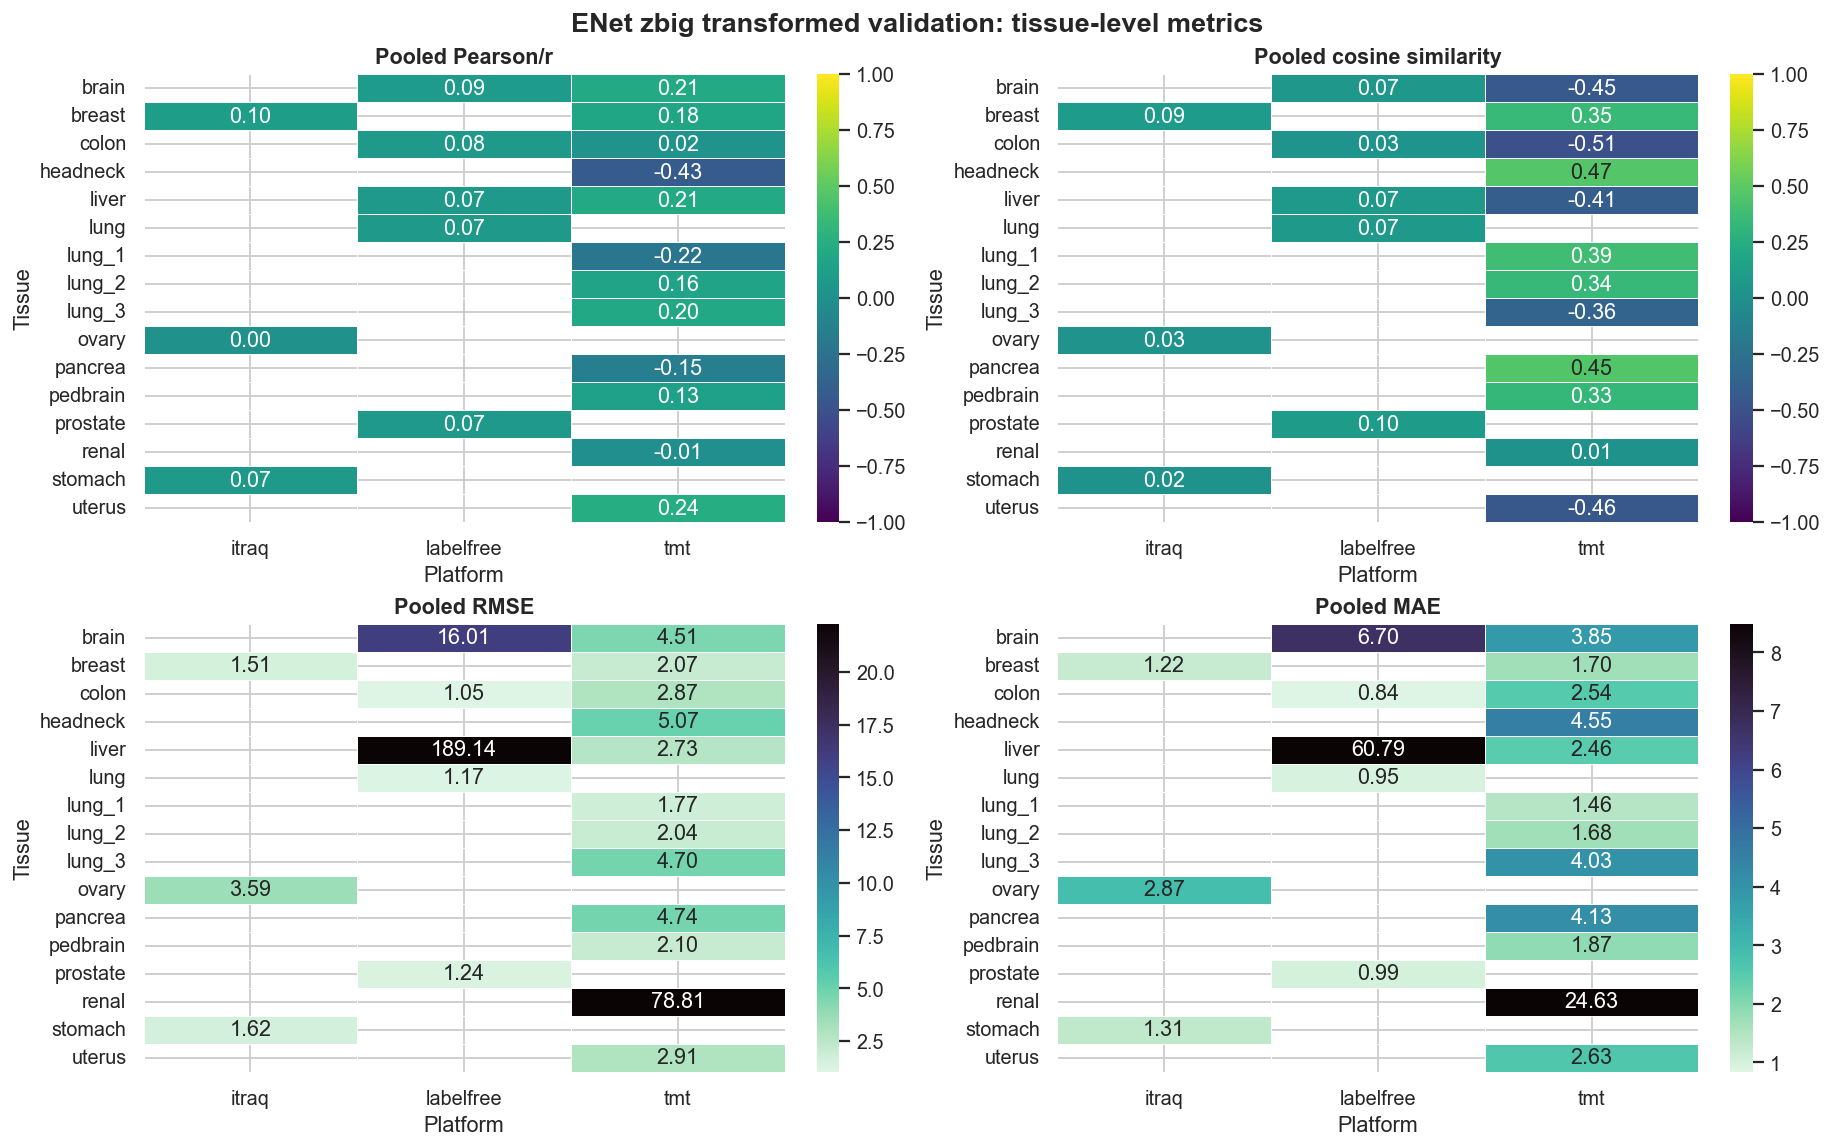

In [13]:

if metrics_by_protein.empty:
    print("No protein metrics available.")
else:
    print("Protein-level summary by dataset/run")
    display(
        metrics_by_protein.groupby(["dataset", "run_label"])
        .agg(
            proteins=("protein", "nunique"),
            median_pearson=("test_pearson_corr", "median"),
            median_spearman=("test_spearman_corr", "median"),
            median_cosine=("test_cosine_similarity", "median"),
            median_rmse=("test_rmse", "median"),
            median_mse=("test_mse", "median"),
            median_missing_fraction=("missing_feature_fraction", "median"),
        )
        .reset_index()
        .sort_values(["dataset", "median_pearson"], ascending=[True, False])
    )

if metrics_by_tissue.empty:
    print("No tissue metrics available.")
else:
    print("Tissue-level summary")
    display(metrics_by_tissue[[c for c in ["ShortName", "dataset", "tissue_for_xu", "samples", "common", "test_pearson_corr", "test_cosine_similarity", "test_rmse", "test_mae", "test_mse"] if c in metrics_by_tissue.columns]])

    metric_specs = [
        ("test_pearson_corr", "Pooled Pearson/r", "viridis", -1, 1),
        ("test_cosine_similarity", "Pooled cosine similarity", "viridis", -1, 1),
        ("test_rmse", "Pooled RMSE", "mako_r", None, None),
        ("test_mae", "Pooled MAE", "mako_r", None, None),
    ]
    fig, axes = plt.subplots(2, 2, figsize=(14, max(6, 0.42 * metrics_by_tissue["tissue_for_xu"].nunique() + 2)), constrained_layout=True)
    fig.suptitle("ENet zbig transformed validation: tissue-level metrics", fontsize=15, fontweight="bold")
    for ax, (metric, title, cmap, vmin, vmax) in zip(axes.ravel(), metric_specs):
        pivot = metrics_by_tissue.pivot_table(index="tissue_for_xu", columns="platform_for_xu", values=metric, aggfunc="median")
        if metric in {"test_rmse", "test_mae"}:
            vals = pivot.to_numpy().ravel()
            vals = vals[np.isfinite(vals)]
            vmax_plot = np.nanpercentile(vals, 90) if len(vals) else None
            sns.heatmap(pivot, ax=ax, cmap=cmap, linewidths=0.4, linecolor="white", annot=True, fmt=".2f", vmax=vmax_plot)
        else:
            sns.heatmap(pivot, ax=ax, cmap=cmap, linewidths=0.4, linecolor="white", annot=True, fmt=".2f", vmin=vmin, vmax=vmax)
        ax.set_title(title)
        ax.set_xlabel("Platform")
        ax.set_ylabel("Tissue")
    fig.savefig(FIG_DIR / "enet_zbig_tissue_metrics_heatmaps.png", bbox_inches="tight")
    plt.show()


## 7. Saved-file summary

In [14]:

print("Saved files for downstream notebooks:")
for p in [
    PREDICTIONS_PARQUET if PREDICTIONS_PARQUET.exists() else PREDICTIONS_CSV,
    METRICS_PROTEIN_CSV,
    FEATURE_COVERAGE_CSV,
    MODEL_INVENTORY_CSV,
    METRICS_TISSUE_CSV,
    METRICS_TISSUE_XU_FORMAT_CSV,
    METRICS_TISSUE_PROTEIN_CSV,
    ENET_ZBIG_XU_FORMAT_CSV,
]:
    print("-", p)
print("\nNotebook 10.5 should read:")
print(METRICS_TISSUE_XU_FORMAT_CSV.resolve())


Saved files for downstream notebooks:
- C:\Users\hp\Desktop\new_pRNA\results_comparison_enet_zbig_transformed\res_enet_zbig__eval_predictions_long.parquet
- C:\Users\hp\Desktop\new_pRNA\results_comparison_enet_zbig_transformed\eval_metrics_by_protein.csv
- C:\Users\hp\Desktop\new_pRNA\results_comparison_enet_zbig_transformed\feature_coverage.csv
- C:\Users\hp\Desktop\new_pRNA\results_comparison_enet_zbig_transformed\model_inventory.csv
- C:\Users\hp\Desktop\new_pRNA\results_comparison_enet_zbig_transformed\eval_metrics_by_tissue.csv
- C:\Users\hp\Desktop\new_pRNA\results_comparison_enet_zbig_transformed\eval_metrics_by_tissue_tableS6_format.csv
- C:\Users\hp\Desktop\new_pRNA\results_comparison_enet_zbig_transformed\eval_metrics_by_tissue_protein.csv
- C:\Users\hp\Desktop\new_pRNA\results_comparison_enet_zbig_transformed\enet_zbig_tissue_metrics_xu_format.csv

Notebook 10.5 should read:
C:\Users\hp\Desktop\new_pRNA\results_comparison_enet_zbig_transformed\eval_metrics_by_tissue_tableS6_